# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
# Run once: installs plotly (+ kaleido so charts can also be saved as static images)
%pip install -q plotly pandas nbformat kaleido

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [3]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 135.3 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <ArrowStringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.

In [4]:
# Helper: show the interactive chart in Jupyter AND embed a static PNG in the notebook,
# because GitHub cannot run plotly's interactive JavaScript but does display PNG outputs.
from IPython.display import Image, display

def show_chart(fig, name):
    fig.show()                                  # interactive (Jupyter)
    fig.write_html(f"{name}.html")              # standalone interactive copy
    try:
        png = fig.to_image(format="png", width=1000, height=620, scale=2)
        with open(f"{name}.png", "wb") as f:
            f.write(png)
        display(Image(png))                     # static copy saved inside the .ipynb (visible on GitHub)
    except Exception as e:
        print("Static PNG not created (kaleido/Chrome missing):", e)
        print("Fix: run  plotly_get_chrome  in a terminal, then re-run this cell.")


## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


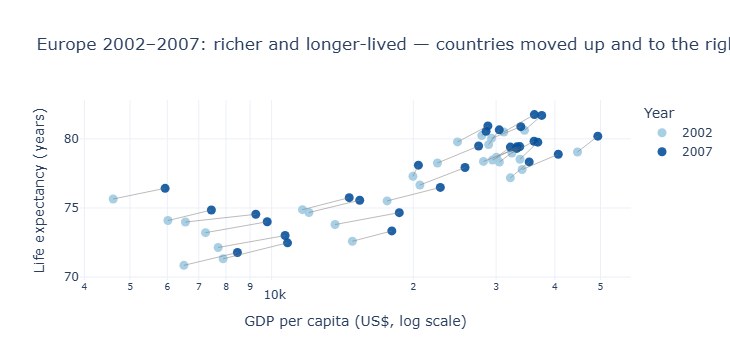

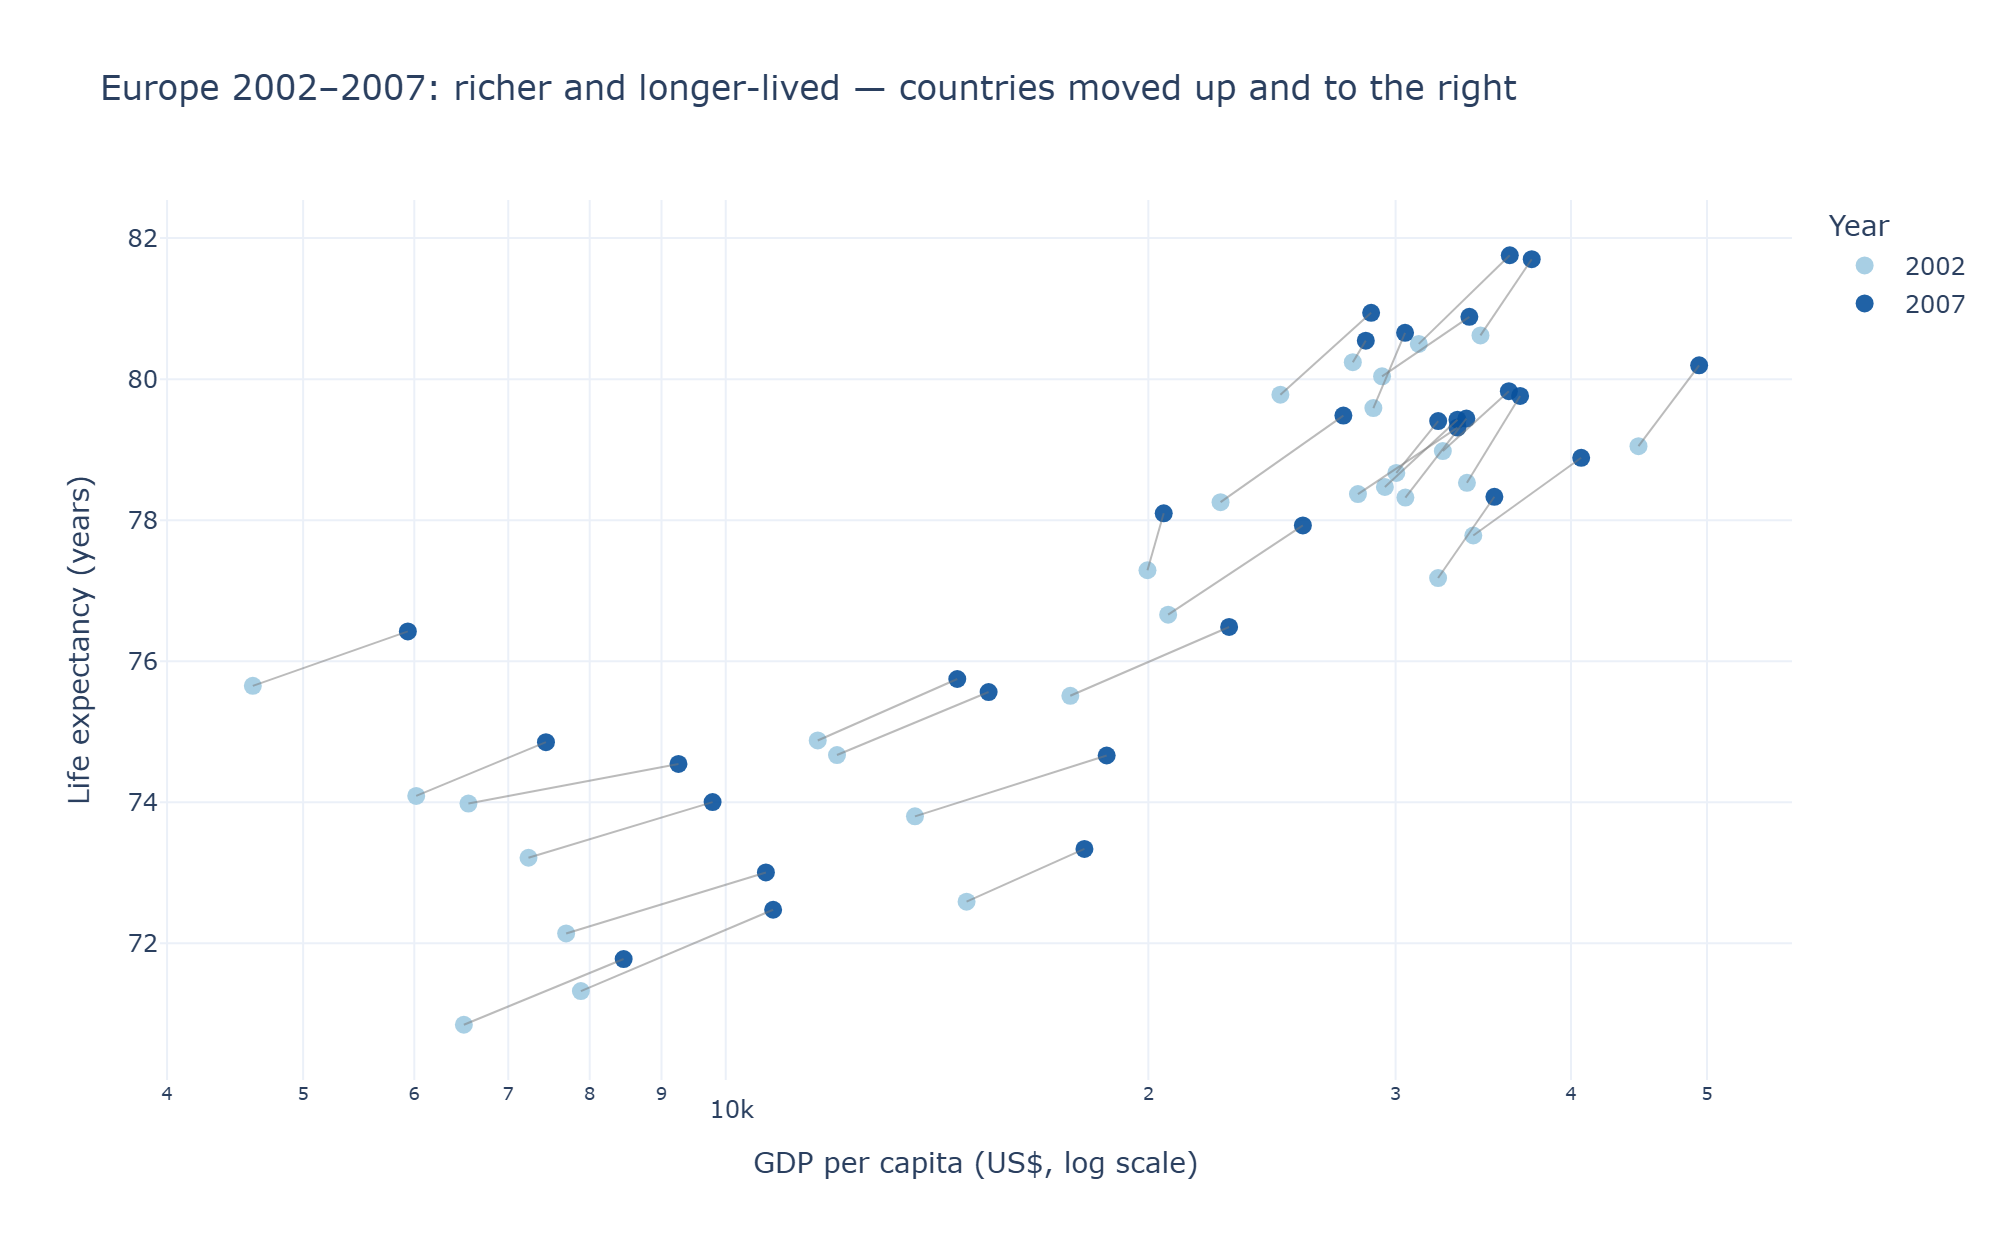

In [5]:
# Task 1 — Europe: GDP per capita vs life expectancy, 2002 vs 2007
import plotly.graph_objects as go

europe = df.loc[(df['continent'] == 'Europe') & (df['year'].isin([2002, 2007]))].copy()
europe['year'] = europe['year'].astype(str)

fig1 = px.scatter(
    europe,
    x='gdpPercap',
    y='lifeExp',
    color='year',
    hover_name='country',
    log_x=True,
    color_discrete_map={'2002': '#9ecae1', '2007': '#08519c'},  # light -> dark = earlier -> later
    labels={'gdpPercap': 'GDP per capita (US$, log scale)',
            'lifeExp': 'Life expectancy (years)',
            'year': 'Year'},
    title='Europe 2002–2007: richer and longer-lived — countries moved up and to the right',
    category_orders={'year': ['2002', '2007']},
)

# Grey connector line per country (2002 -> 2007) to show the direction of change.
# One trace, with None separating the countries.
xs, ys = [], []
for _, g in europe.sort_values('year').groupby('country'):
    xs += list(g['gdpPercap']) + [None]
    ys += list(g['lifeExp']) + [None]

fig1.add_trace(go.Scatter(
    x=xs, y=ys, mode='lines',
    line=dict(color='rgba(120,120,120,0.5)', width=1),
    hoverinfo='skip', showlegend=False,
))

fig1.update_traces(marker=dict(size=9, opacity=0.9), selector=dict(mode='markers'))
fig1.update_layout(template='plotly_white', legend_title_text='Year')
show_chart(fig1, "task1_europe_scatter")


## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


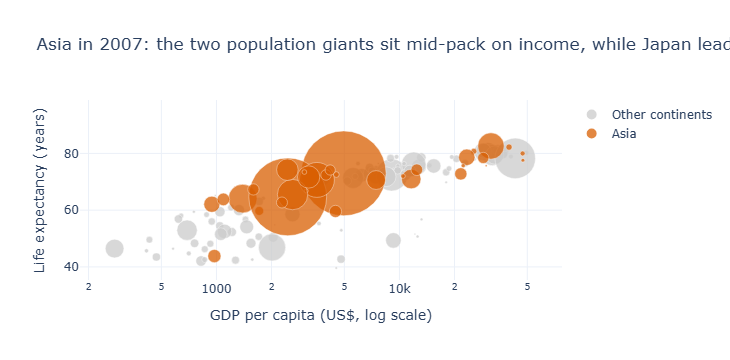

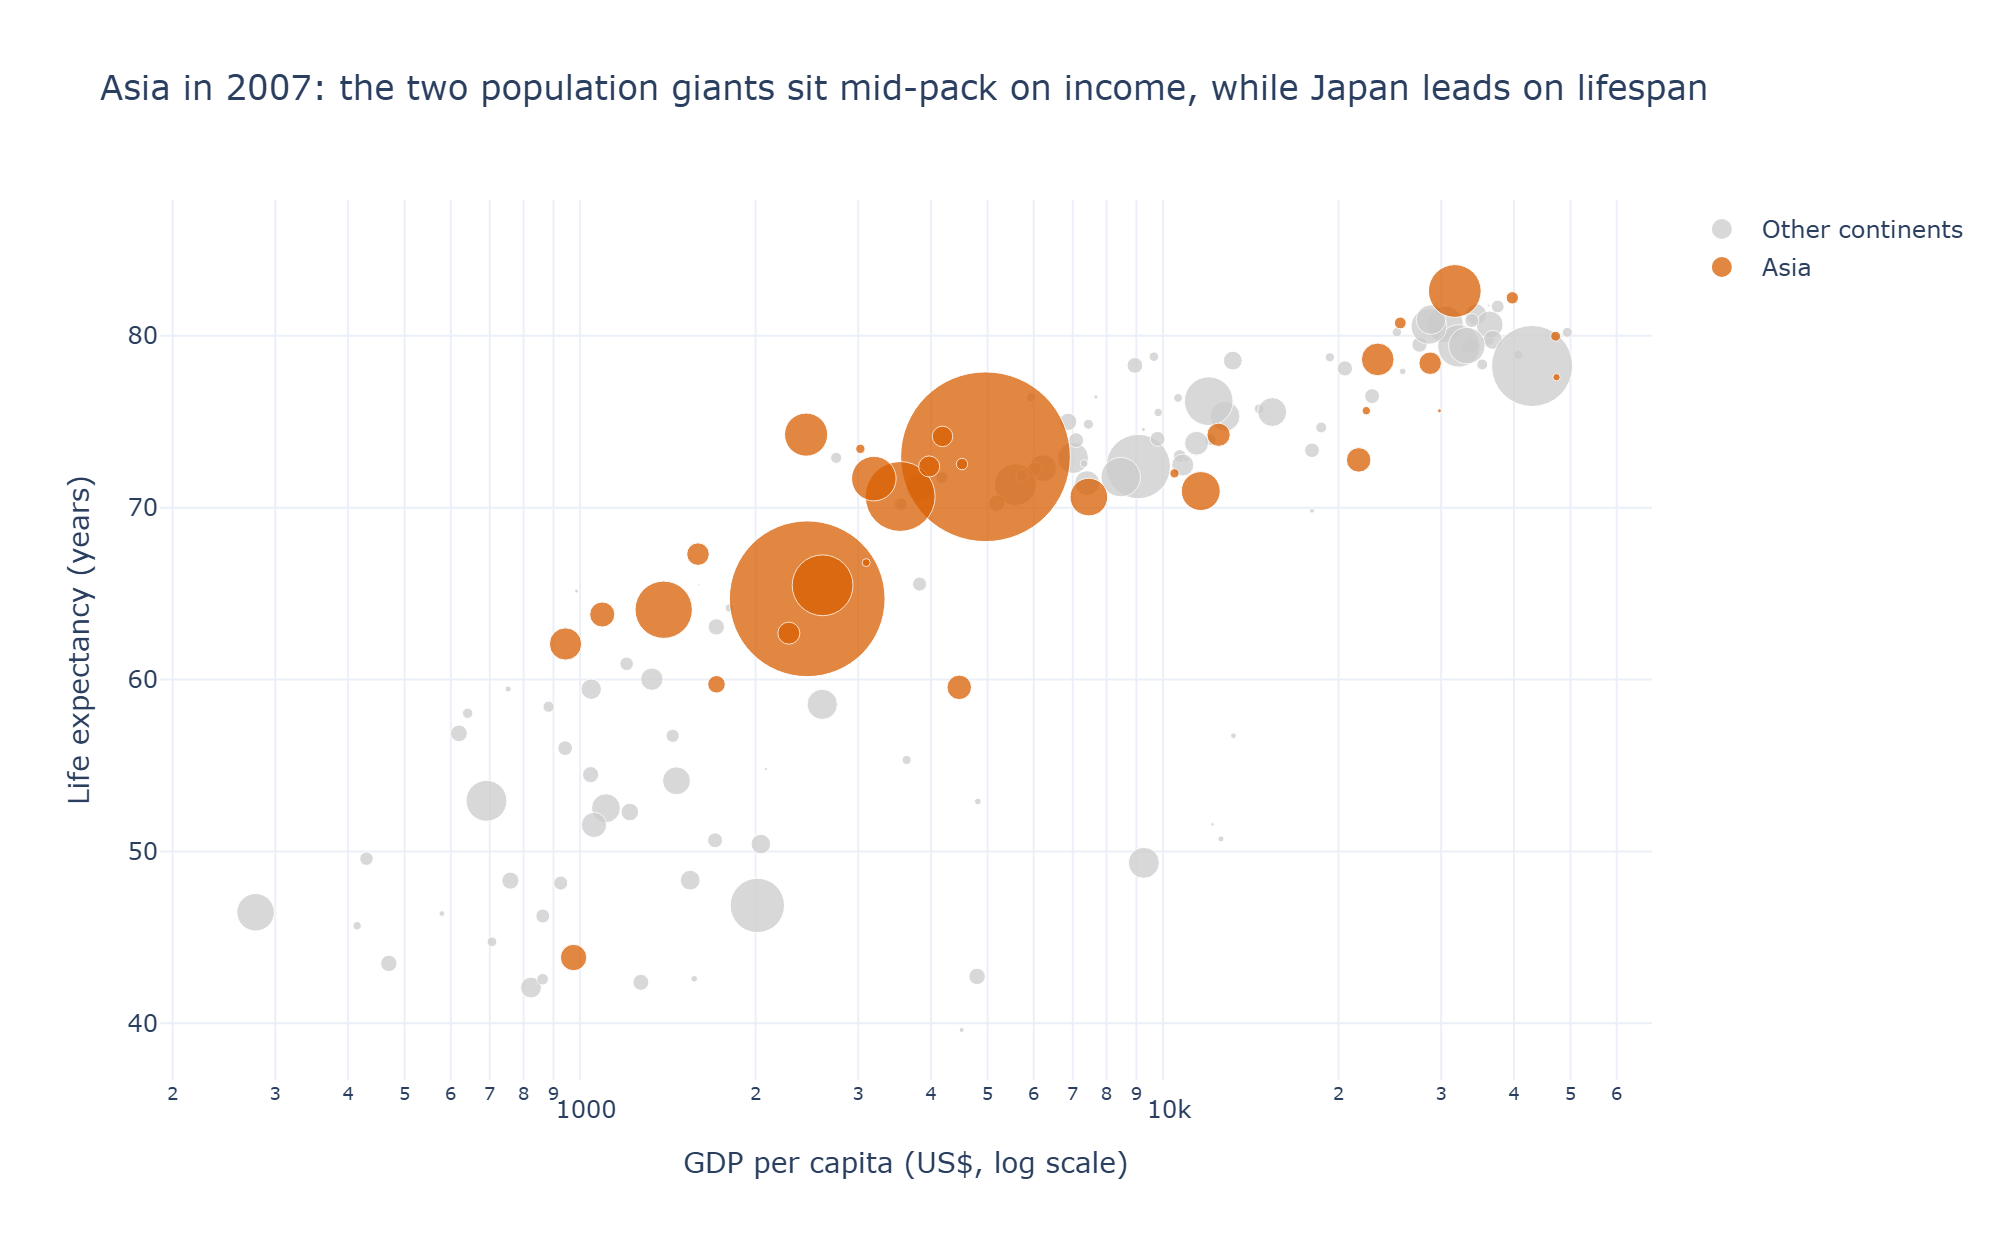

In [6]:
# Task 2 — Bubble chart, 2007, Asia highlighted, others grey
d07 = df.loc[df['year'] == 2007].copy()
highlight = 'Asia'
d07['group'] = d07['continent'].where(d07['continent'] == highlight, 'Other continents')

fig2 = px.scatter(
    d07,
    x='gdpPercap',
    y='lifeExp',
    size='pop',
    size_max=60,
    color='group',
    hover_name='country',
    log_x=True,
    color_discrete_map={highlight: '#d95f02', 'Other continents': '#cccccc'},
    category_orders={'group': ['Other continents', highlight]},  # draw grey first, highlight on top
    labels={'gdpPercap': 'GDP per capita (US$, log scale)',
            'lifeExp': 'Life expectancy (years)',
            'group': ''},
    title='Asia in 2007: the two population giants sit mid-pack on income, while Japan leads on lifespan',
)

fig2.update_traces(marker=dict(opacity=0.75, line=dict(width=0.5, color='white')))

def label(country, text, ax=40, ay=-40):
    r = d07.loc[d07['country'] == country].iloc[0]
    fig2.add_annotation(x=r['gdpPercap'], y=r['lifeExp'], xref='x', yref='y',
                        text=text, showarrow=True, arrowhead=2,
                        ax=ax, ay=ay, font=dict(size=11, color='#7f3b08'))

label('China', 'China: 1.3bn people,<br>mid income, ~73 yrs', ax=-20, ay=60)
label('India', 'India: 1.1bn people,<br>lower income, ~64 yrs', ax=40, ay=60)
label('Japan', 'Japan: highest life<br>expectancy (~82 yrs)', ax=-40, ay=-30)

fig2.update_layout(template='plotly_white', legend_title_text='')
show_chart(fig2, "task2_bubble_2007")
